# Overview

Our Final Project Goal is train an XGBoost Model for stock prediction, based on chosen stock name. The Strucutre is following:
* Input of Stock Name
* Data is retervived from google cloud and processed into Daily Values
* XGBoost Model is trained on that data by looking a sliding window of 90 Days for 10 Epochs.
* Predict where a stock will increase or decrease the next day alongside confidence value. Weights will be saved to google cloud

For this sprint, we have decided to make one change; Our oringinal dataset contains minute by minute data of stocks. This is useful, but for machine learning and anaylsis, can produce noise that hides important info. We saw this in sprint 3, were our montly anayslsis of increases was uniform, and didn't really tell us much. As such we have decided to convert our minute by minute data into daily data. As that get rid of unncessary noise, while still containing someuseful information.

## Set up
Installing pyspark and setting up local session. Cloning Repo to access sample data.

In [3]:
%pip -q install pyspark==4.0.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window


In [5]:
spark = (SparkSession.builder
    .appName("CS131-Class19")
    .master("local[2]")
    .getOrCreate())

In [6]:
!git clone https://github.com/sjsu-cs131-f26/7thStWolf-Nifty100-Stock.git

fatal: destination path '7thStWolf-Nifty100-Stock' already exists and is not an empty directory.


In [7]:
path_to_sprint3_sample = '/content/7thStWolf-Nifty100-Stock/pa3/data/sample' # Ignore this

In [8]:
sprint4_sample = '/content/7thStWolf-Nifty100-Stock/pa4/data/sample'

# Task 1

We also be using the data sample from Sprint 3 from our repo for this.
For Task 1:
* We converted minute by minute data into daily data
* Inspect its schema, select fields, and set appropriate types
* Create new column; change_pc - Measure of close changed from yesterday, using the following formula: (close_today − close_yesterday) / close_yesterday × 100
* Save the file as parquet

In [9]:
data = spark.read.option('header', 'true').option("inferSchema", True).option("sep", "\t").csv(path_to_sprint3_sample)

In [10]:
data.head()

Row(name='APOLLOHOSP', date=datetime.datetime(2015, 2, 2, 9, 15), open=1350.0, high=1350.0, low=1315.3, close=1325.0, volume=1104, price_change='None', volume_change='None')

In [11]:
def minute_to_daily(data, path=None):
  """
  Coverts Minute by minute by minute stock data to daily data.

  Grouping by day and then finding this:
  Daily Open - Open value at the first minute of the day
  Daily High - Largest value from high column across the entire day
  Daily Low - Smallest value from the low column aross the entire day
  Daily close - Close value at the last minute at the day


  """
  if path:
    data = spark.read.option('header', 'true').option("inferSchema", True).csv(path)
  data = data.withColumnRenamed('date', 'datetime')
  data = data.withColumn('date', F.to_date('datetime'))

  daily_data = data.groupby('date').agg(
      F.min_by("open", 'datetime').alias('open'), # This line takes the open prices from the first minute of day
      F.max('high').alias('high'), # This lines takes the max high across the entire day and sets it as high
      F.min('low').alias('low'), # This lines takes the min low across the entire day and sets it as low
      F.max_by("close", 'datetime').alias("close") # This lines takes the close price from the last minute of the day
  ).orderBy('date')

  #This only has date, open, high, low and close. We need to get Price Change back again.

  daily_data = daily_data.withColumn('prev_close', F.lag('close', 1).over(Window.orderBy('date')))
  # Creates a temp column thats a copy of close, but shifted by 1 day to create price_change
  daily_data = daily_data.withColumn('price_change', F.when(
      F.col('prev_close').isNull(), 'None')
        .when(F.col('close') > F.col('prev_close'), 'Increased')
        .when(F.col('close') < F.col('prev_close'), 'Decreased')
        .otherwise('None')
        )

  daily_data = daily_data.drop('prev_close') # drop prev_close

  return daily_data


In [12]:
daily_data = minute_to_daily(data)

In [13]:
print('The Schema of our dataset is: ')
daily_data.printSchema()

The Schema of our dataset is: 
root
 |-- date: date (nullable = true)
 |-- open: double (nullable = true)
 |-- high: double (nullable = true)
 |-- low: double (nullable = true)
 |-- close: double (nullable = true)
 |-- price_change: string (nullable = false)



In [14]:
print("""The Two Rules we will be applying are:
  1. high >= Low
  2. low <= close <= high
  3. low <= open <= high
""")

The Two Rules we will be applying are:
  1. high >= Low
  2. low <= close <= high
  3. low <= open <= high



In [15]:
print(f'Before Filtering our dataset has: {daily_data.count()} Days')

Before Filtering our dataset has: 2769 Days


In [16]:
daily_data = daily_data.filter(
    F.col('low') <= F.col('high')).filter(
    (F.col('low')<= F.col('open')) & (F.col('open')<= F.col('high'))).filter(
         (F.col('low')<= F.col('close')) & (F.col('close')<= F.col('high'))
    )


In [17]:
print(f'After Filtering our dataset has: {daily_data.count()} Days')

After Filtering our dataset has: 2769 Days


In [18]:
print('All rows are valid')

All rows are valid


In [19]:
def create_percent_change(data):
  data = data.withColumn('prev_close', F.lag('close', 1).over(Window.orderBy('date')))
  data = data.withColumn('change_pc', F.round(((F.col('close') - F.col('prev_close')) / F.col('prev_close'))*100, 2))
  data = data.fillna({"change_pc": 0}) # The first row will have it as none, so we should just change it 0.
  data = data.drop('prev_close')
  return data

In [20]:
daily_data = create_percent_change(daily_data)
daily_data.head(5)

[Row(date=datetime.date(2015, 2, 2), open=1350.0, high=1358.7, low=1310.1, close=1353.0, price_change='None', change_pc=0.0),
 Row(date=datetime.date(2015, 2, 3), open=1354.0, high=1355.05, low=1287.05, close=1300.0, price_change='Decreased', change_pc=-3.92),
 Row(date=datetime.date(2015, 2, 4), open=1301.0, high=1328.35, low=1299.95, close=1305.25, price_change='Increased', change_pc=0.4),
 Row(date=datetime.date(2015, 2, 5), open=1314.95, high=1332.0, low=1288.55, close=1292.65, price_change='Decreased', change_pc=-0.97),
 Row(date=datetime.date(2015, 2, 6), open=1299.0, high=1301.85, low=1257.55, close=1267.45, price_change='Decreased', change_pc=-1.95)]

In [21]:
daily_data.printSchema()

root
 |-- date: date (nullable = true)
 |-- open: double (nullable = true)
 |-- high: double (nullable = true)
 |-- low: double (nullable = true)
 |-- close: double (nullable = true)
 |-- price_change: string (nullable = false)
 |-- change_pc: double (nullable = false)



In [22]:
daily_data.groupby('date').count().filter('count > 1').count()

0

In [23]:
from functools import reduce
null_condition = reduce(lambda a, b: a | b, [F.col(c).isNull() for c in daily_data.columns])
daily_data.filter(null_condition).count()

0

In [24]:
numeric_cols = ['open', 'high', 'low', 'close']
negative_conditoins = reduce(lambda a, b: a | b, [F.col(c) < 0 for c in numeric_cols])
daily_data.filter(negative_conditoins).count()

0

For our anyalsis we only need date, price_change and change_pc. All other columns can be dropped.

In [25]:
sample = daily_data.select('date', 'price_change', 'change_pc')
sample.head()

Row(date=datetime.date(2015, 2, 2), price_change='None', change_pc=0.0)

In [26]:
sample.write.mode("append").parquet('/content')

In [27]:
# Testing writing and read:

#data = spark.read.option('header', 'true').option("inferSchema", True).parquet('/content/sample.parquet')
#data.head(5)
#print(data.count())

# Creating Checks

In [28]:
checks = []
def check( cat, desc, value, note=''):
  checks.append(dict( category=cat,description=desc, value=value, note=note))

In [29]:
check('Row Definition', 'What one row represnetns', 'A Day of a stock with opens, close, low and highest values alongside if it changed from it yesterday and by what percent')
check('Row Count', "Raw Row Count",  2769)
check('Row Count', "Row count after filtering", 2769)
check('data type', 'date', 'Datetime.date')
check('data type', 'open', 'double')
check('data type', 'close', 'double')
check('data type', 'low', 'double')
check('data type', 'high', 'double')
check('data type', 'price_change', 'string')
check('data type', 'change', 'double ')
check('missing', 'Rows with Null Values', 0)
check('domain check', '# of invalid values(negative)', 0)
check('parquet', 'read row count', 2769)
check('parquet', 'same types', True)
check('domain key checks', 'low <= High', True)
check('domain key checks', 'low <= open <= High', True)
check('domain key checks', 'low <= close <= High', True)
check('key uniquess', 'is Date unique', daily_data.groupby('date').count().filter('count > 1').count()==0)

In [30]:
import pandas as pd

In [31]:
checks = pd.DataFrame(checks)
checks.to_csv('/content/quality_checks.csv')

Final Summary of Task 1:
* Sample Row Counts: 100
* Date is Unique and can be considered the primary key
* We have date, double, and strings as dataypes in our dataset
* The Project specific rules we used were: Low <= High, Low <= Open <= High, Low <= Close <= High

# Task 2: Answer two analytical questions

Inputs: Analysis 1 reproduces the PA3 benchmark and so needs the minute-level records (`path_to_sprint3_sample`). Analysis 2 uses the daily table built from those same records.

* **Analysis 1 (PA3 reproduction):** for each calendar month, how many minute records *increased*, how many were comparable (increased + decreased), and the ratio. Same filters, grouping, `None` rule, 4-decimal rounding and month ordering as PA3.
* **Analysis 2:** what is the average daily `change_pc` for each calendar month, regardless of year? Includes a **join** and a **window** (rank of months).

In [32]:
import os, shutil
import pandas as pd

REPO = '/content/7thStWolf-Nifty100-Stock'
PA4  = f'{REPO}/pa4'
OUT  = f'{PA4}/out'                     # analysis_1.csv, analysis_2.csv, quality_checks.csv, sample_comparison.csv
DOCS = f'{PA4}/docs'
SAMP = f'{PA4}/data/sample'             # lookup
PREP = f'{PA4}/data/prepared'           # daily / train / test / dev-sample Parquet
for d in (OUT, DOCS, SAMP, PREP):
    os.makedirs(d, exist_ok=True)

spark.conf.set('spark.sql.shuffle.partitions', 8)
MINUTE_PATH = path_to_sprint3_sample    # minute-level TSV (single stock)

def save_csv(sdf, path, **kw):
    """Spark -> ONE real CSV file with a header (not a part-file directory)."""
    sdf.toPandas().to_csv(path, index=False, **kw)
    print('wrote', path)

## Analysis 1 : PA3 reproduction

PA3's prep script read all columns as text, lower-cased `price_change`, and **rejected** a row if (in this order) the timestamp format was wrong, the month was outside 1-12, `close` was not a positive number, `high`/`low` were not numeric or `high < low`, or `price_change` was not one of increased/decreased/none. It did **not** check `open`/`close` against the high-low range, so we do not either. Each rejected row is counted once, under the *first* rule it fails, so the reason counts add up without double counting.

In [33]:
raw_minute = (spark.read.option('header', True).option('sep', '\t').csv(MINUTE_PATH))   # all strings, like PA3's awk step

pc    = F.lower(F.col('price_change'))
close = F.col('close').cast('double')
high  = F.col('high').cast('double')
low   = F.col('low').cast('double')

reason = (F.when(~F.col('date').rlike(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$'), 'bad_timestamp')
           .when(~F.substring('date', 6, 2).cast('int').between(1, 12), 'bad_month')
           .when(close.isNull() | (close <= 0), 'bad_close')
           .when(high.isNull() | low.isNull() | (high < low), 'bad_high_low')
           .when(~pc.isin('increased', 'decreased', 'none'), 'bad_price_change'))

tagged = raw_minute.withColumn('reject_reason', reason)
valid_minute    = tagged.filter(F.col('reject_reason').isNull())
rejected_minute = tagged.filter(F.col('reject_reason').isNotNull())

n_raw_minute      = raw_minute.count()
n_valid_minute    = valid_minute.count()
n_rejected_minute = rejected_minute.count()
print('input rows   :', n_raw_minute)
print('rejected rows:', n_rejected_minute)
print('valid rows   :', n_valid_minute)
assert n_valid_minute + n_rejected_minute == n_raw_minute
rejected_minute.groupBy('reject_reason').count().show()
print('distinct stocks in input:', raw_minute.select('name').distinct().count())

input rows   : 1033587
rejected rows: 0
valid rows   : 1033587
+-------------+-----+
|reject_reason|count|
+-------------+-----+
+-------------+-----+

distinct stocks in input: 1


In [34]:
a1 = (valid_minute
      .withColumn('pc', F.lower('price_change'))
      .filter(F.col('pc').isin('increased', 'decreased'))          # 'none' rows do not contribute
      .withColumn('month', F.substring('date', 6, 2).cast('int'))  # same as PA3: month text of the timestamp
      .groupBy('month')
      .agg(F.sum(F.when(F.col('pc') == 'increased', 1).otherwise(0)).cast('long').alias('increase_count'),
           F.count('*').alias('compared_rows'))
      .withColumn('increase_ratio', F.round(F.col('increase_count') / F.col('compared_rows'), 4))
      .orderBy('month'))
a1.cache()
a1.show(12)

n_none_minute = valid_minute.filter(F.lower('price_change') == 'none').count()
print('valid rows with price_change = none (excluded from analysis):', n_none_minute)
print('compared rows total:', a1.agg(F.sum('compared_rows')).first()[0])
assert a1.agg(F.sum('compared_rows')).first()[0] + n_none_minute == n_valid_minute

+-----+--------------+-------------+--------------+
|month|increase_count|compared_rows|increase_ratio|
+-----+--------------+-------------+--------------+
|    1|         40634|        81372|        0.4994|
|    2|         41969|        84465|        0.4969|
|    3|         42240|        84758|        0.4984|
|    4|         37039|        73972|        0.5007|
|    5|         39971|        80460|        0.4968|
|    6|         40141|        80905|        0.4961|
|    7|         41138|        81898|        0.5023|
|    8|         39778|        80091|        0.4967|
|    9|         39154|        78564|        0.4984|
|   10|         37761|        75986|        0.4969|
|   11|         37787|        75913|        0.4978|
|   12|         40344|        81506|         0.495|
+-----+--------------+-------------+--------------+

valid rows with price_change = none (excluded from analysis): 73697
compared rows total: 959890


In [35]:
# Compare with the PA3 DuckDB result (from out/duckdb_text_result.tsv, APOLLOHOSP).
pa3_rows = [(1,40634,81372,0.4994),(2,41969,84465,0.4969),(3,42240,84758,0.4984),(4,37039,73972,0.5007),
            (5,39971,80460,0.4968),(6,40141,80905,0.4961),(7,41138,81898,0.5023),(8,39778,80091,0.4967),
            (9,39154,78564,0.4984),(10,37761,75986,0.4969),(11,37787,75913,0.4978),(12,40344,81506,0.4950)]
pa3_df = pd.DataFrame(pa3_rows, columns=['month','increase_count','compared_rows','increase_ratio'])

a1_pd = a1.toPandas().sort_values('month').reset_index(drop=True)
m = pa3_df.merge(a1_pd, on='month', how='outer', suffixes=('_pa3', '_pa4'))
m['count_match'] = (m.increase_count_pa3 == m.increase_count_pa4) & (m.compared_rows_pa3 == m.compared_rows_pa4)
m['ratio_match'] = (m.increase_ratio_pa3 - m.increase_ratio_pa4).abs() < 1e-4
print(m.to_string(index=False))
print('\nall 12 months match PA3:', bool(m.count_match.all() and m.ratio_match.all()))
# If this prints False, the minute file in the repo is not the same record set PA3 used: compare row counts first.

 month  increase_count_pa3  compared_rows_pa3  increase_ratio_pa3  increase_count_pa4  compared_rows_pa4  increase_ratio_pa4  count_match  ratio_match
     1               40634              81372              0.4994               40634              81372              0.4994         True         True
     2               41969              84465              0.4969               41969              84465              0.4969         True         True
     3               42240              84758              0.4984               42240              84758              0.4984         True         True
     4               37039              73972              0.5007               37039              73972              0.5007         True         True
     5               39971              80460              0.4968               39971              80460              0.4968         True         True
     6               40141              80905              0.4961               40141         

In [36]:
save_csv(a1, f'{OUT}/analysis_1.csv', float_format='%.4f')   # ordered by month, ratio shown to 4 decimals
print(open(f'{OUT}/analysis_1.csv').read())

wrote /content/7thStWolf-Nifty100-Stock/pa4/out/analysis_1.csv
month,increase_count,compared_rows,increase_ratio
1,40634,81372,0.4994
2,41969,84465,0.4969
3,42240,84758,0.4984
4,37039,73972,0.5007
5,39971,80460,0.4968
6,40141,80905,0.4961
7,41138,81898,0.5023
8,39778,80091,0.4967
9,39154,78564,0.4984
10,37761,75986,0.4969
11,37787,75913,0.4978
12,40344,81506,0.4950



### Baseline audit of PA3

PA3 trusted the supplied `price_change` label. Here we recompute the label from `close` (compared with the previous minute's `close`, ordered by timestamp) and count disagreements, so any baseline error is measured instead of assumed.

In [37]:
ts_w = Window.partitionBy('name').orderBy('ts')
audit = (valid_minute
         .withColumn('ts', F.to_timestamp('date'))
         .withColumn('close_d', F.col('close').cast('double'))
         .withColumn('prev_close', F.lag('close_d').over(ts_w))
         .withColumn('is_first_of_day', F.to_date('ts') != F.lag(F.to_date('ts')).over(ts_w))
         .withColumn('recomputed',
                     F.when(F.col('prev_close').isNull(), 'none')
                      .when(F.col('close_d') > F.col('prev_close'), 'increased')
                      .when(F.col('close_d') < F.col('prev_close'), 'decreased')
                      .otherwise('none'))
         .withColumn('supplied', F.lower('price_change')))

audit.groupBy('is_first_of_day').agg(
    F.count('*').alias('rows'),
    F.sum((F.col('recomputed') != F.col('supplied')).cast('int')).alias('label_mismatches')).show()

n_mismatch = audit.filter(F.col('recomputed') != F.col('supplied')).count()
print('total label mismatches:', n_mismatch, 'of', n_valid_minute)
audit.filter(F.col('recomputed') != F.col('supplied')).select('date', 'close', 'price_change', 'prev_close', 'recomputed').show(5, False)

+---------------+-------+----------------+
|is_first_of_day|   rows|label_mismatches|
+---------------+-------+----------------+
|           NULL|      1|               0|
|           true|   2768|               0|
|          false|1030818|               0|
+---------------+-------+----------------+

total label mismatches: 0 of 1033587
+----+-----+------------+----------+----------+
|date|close|price_change|prev_close|recomputed|
+----+-----+------------+----------+----------+
+----+-----+------------+----------+----------+



## Daily table for Analysis 2 and Task 3

Same logic as the Task 1 function, with three changes needed downstream: it keeps `name` (windows are `partitionBy('name')`, so the same code works if a multi-stock file is used), keeps a daily `volume` (sum of minutes) and `minute_rows`, and leaves the first day's `change_pc` as **null** instead of 0 (a fake 0% day would bias monthly averages; averages ignore nulls). For one stock the results are identical to Task 1 apart from that first day.

In [38]:
def minute_to_daily_v2(m):
    m = (m.withColumn('ts', F.to_timestamp('date')).withColumn('day', F.to_date('ts'))
          .withColumn('open', F.col('open').cast('double')).withColumn('high', F.col('high').cast('double'))
          .withColumn('low', F.col('low').cast('double')).withColumn('close', F.col('close').cast('double'))
          .withColumn('volume', F.col('volume').cast('double')))
    d = (m.groupBy('name', 'day')
          .agg(F.min_by('open', 'ts').alias('open'),
               F.max('high').alias('high'),
               F.min('low').alias('low'),
               F.max_by('close', 'ts').alias('close'),
               F.sum('volume').alias('volume'),
               F.count('*').alias('minute_rows'))
          .withColumnRenamed('day', 'date'))
    w = Window.partitionBy('name').orderBy('date')
    d = d.withColumn('prev_close', F.lag('close').over(w))
    d = (d.withColumn('price_change',
                      F.when(F.col('prev_close').isNull(), 'None')
                       .when(F.col('close') > F.col('prev_close'), 'Increased')
                       .when(F.col('close') < F.col('prev_close'), 'Decreased')
                       .otherwise('None'))
          .withColumn('change_pc', F.round((F.col('close') - F.col('prev_close')) / F.col('prev_close') * 100, 2))
          .drop('prev_close'))
    return d.orderBy('name', 'date')

daily_raw = minute_to_daily_v2(valid_minute)
n_daily_raw = daily_raw.count()

# Same Task 1 domain rules, applied to the daily values
ok = ((F.col('low') <= F.col('high')) & F.col('open').between(F.col('low'), F.col('high'))
      & F.col('close').between(F.col('low'), F.col('high')))
daily_df = daily_raw.filter(ok)
n_daily = daily_df.count()
print('daily rows before domain filter:', n_daily_raw, '| after:', n_daily, '| removed:', n_daily_raw - n_daily)
print('distinct (name,date) keys == rows:', daily_df.select('name', 'date').distinct().count() == n_daily)
print('distinct stocks:', daily_df.select('name').distinct().count())
daily_df.printSchema()
daily_df.show(5)

daily rows before domain filter: 2769 | after: 2769 | removed: 0
distinct (name,date) keys == rows: True
distinct stocks: 1
root
 |-- name: string (nullable = true)
 |-- date: date (nullable = true)
 |-- open: double (nullable = true)
 |-- high: double (nullable = true)
 |-- low: double (nullable = true)
 |-- close: double (nullable = true)
 |-- volume: double (nullable = true)
 |-- minute_rows: long (nullable = false)
 |-- price_change: string (nullable = false)
 |-- change_pc: double (nullable = true)

+----------+----------+-------+-------+-------+-------+--------+-----------+------------+---------+
|      name|      date|   open|   high|    low|  close|  volume|minute_rows|price_change|change_pc|
+----------+----------+-------+-------+-------+-------+--------+-----------+------------+---------+
|APOLLOHOSP|2015-02-02| 1350.0| 1358.7| 1310.1| 1353.0|200461.0|        375|        None|     NULL|
|APOLLOHOSP|2015-02-03| 1354.0|1355.05|1287.05| 1300.0|160647.0|        375|   Decreased| 

In [39]:
DAILY_PATH = f'{PREP}/daily_full.parquet'
daily_df.write.mode('overwrite').parquet(DAILY_PATH)
daily_rb = spark.read.parquet(DAILY_PATH)
print('read-back count :', daily_rb.count(), '(expected', n_daily, ')')
print('same schema     :', daily_rb.dtypes == daily_df.dtypes)   # names + types (Parquet drops the not-null flag)
tot_src = daily_df.agg(F.sum('volume')).first()[0]; tot_rb = daily_rb.agg(F.sum('volume')).first()[0]
print('total volume    :', tot_src, tot_rb, tot_src == tot_rb)
daily_df = daily_rb      # continue from the persisted table

read-back count : 2769 (expected 2769 )
same schema     : True
total volume    : 1579370454.0 1579370454.0 True


## Analysis 2 - average daily change by calendar month

**Question:** is there a month of the year in which stocks tend to rise or fall more, regardless of year? Unit of analysis is a trading day; grouping is by calendar month number (1-12) across all years.

**Join:** `daily_df.month_num` (many daily rows) -> `month_lookup.month_num` (exactly one row per month): many-to-one, so the join must not change the row count.
**Window:** rank the 12 months by average `change_pc`, descending; tied averages share a rank (`rank()`), ties are listed in month order. Whole-table window, default frame (the ranking looks at all 12 rows).

In [40]:
lookup_pd = pd.DataFrame({'month_num': range(1, 13),
    'month_name': ['January','February','March','April','May','June','July','August','September','October','November','December'],
    'quarter': ['Q1']*3 + ['Q2']*3 + ['Q3']*3 + ['Q4']*3})
lookup_pd.to_csv(f'{SAMP}/month_lookup.csv', index=False)
lookup = spark.read.option('header', True).option('inferSchema', True).csv(f'{SAMP}/month_lookup.csv')

# join checks
dup_keys = lookup.groupBy('month_num').count().filter('count > 1').count()
base = daily_df.withColumn('month_num', F.month('date'))
n_before = base.count()
unmatched = base.join(lookup, 'month_num', 'left_anti').count()
joined = base.join(lookup, 'month_num', 'left')
n_after = joined.count()
print('duplicate lookup keys :', dup_keys)
print('unmatched daily rows  :', unmatched)
print('rows before / after   :', n_before, n_after, '-> unchanged:', n_before == n_after)
assert dup_keys == 0 and unmatched == 0 and n_before == n_after

duplicate lookup keys : 0
unmatched daily rows  : 0
rows before / after   : 2769 2769 -> unchanged: True


In [41]:
mw = Window.orderBy(F.desc('avg_change_pc'))

a2 = (joined.groupBy('month_num', 'month_name', 'quarter')
      .agg(F.count('change_pc').alias('n_days'),                                      # non-null change_pc days
           F.round(F.avg('change_pc'), 4).alias('avg_change_pc'),
           F.round(F.stddev('change_pc'), 4).alias('std_change_pc'),
           F.round(F.avg(F.when(F.col('change_pc') > 0, 1.0).otherwise(0.0)), 4).alias('pct_up_days'))
      .withColumn('rank_by_avg', F.rank().over(mw))
      .orderBy('month_num'))
a2.cache()
a2.show(12, False)

# Manual verification of one group (month 1) against pandas
pdf = daily_df.select('date', 'change_pc').toPandas()
pdf['m'] = pd.to_datetime(pdf['date']).dt.month
jan = pdf[(pdf.m == 1) & pdf.change_pc.notna()].change_pc
spark_jan = a2.filter('month_num = 1').first()
print('pandas   Jan: n=%d avg=%.4f' % (len(jan), jan.mean()))
print('spark    Jan: n=%d avg=%.4f' % (spark_jan['n_days'], spark_jan['avg_change_pc']))
assert len(jan) == spark_jan['n_days'] and abs(jan.mean() - spark_jan['avg_change_pc']) < 1e-4

# Rank check: best month by hand
best = pdf[pdf.change_pc.notna()].groupby('m').change_pc.mean().round(4).sort_values(ascending=False)
print('best month by hand:', best.index[0], '| spark rank-1 month(s):', [r.month_num for r in a2.filter('rank_by_avg = 1').collect()])

+---------+----------+-------+------+-------------+-------------+-----------+-----------+
|month_num|month_name|quarter|n_days|avg_change_pc|std_change_pc|pct_up_days|rank_by_avg|
+---------+----------+-------+------+-------------+-------------+-----------+-----------+
|1        |January   |Q1     |234   |0.0724       |1.7342       |0.5171     |7          |
|2        |February  |Q1     |240   |0.1092       |2.3017       |0.4896     |6          |
|3        |March     |Q1     |242   |-0.262       |2.3688       |0.4504     |12         |
|4        |April     |Q2     |212   |0.1125       |2.1067       |0.4906     |5          |
|5        |May       |Q2     |233   |-0.0729      |1.8117       |0.4592     |11         |
|6        |June      |Q2     |232   |0.2568       |1.8389       |0.5259     |1          |
|7        |July      |Q3     |240   |0.2308       |1.5381       |0.5542     |3          |
|8        |August    |Q3     |229   |0.1717       |2.3058       |0.4629     |4          |
|9        

In [42]:
save_csv(a2, f'{OUT}/analysis_2.csv')          # ordered by month_num
print(open(f'{OUT}/analysis_2.csv').read())

wrote /content/7thStWolf-Nifty100-Stock/pa4/out/analysis_2.csv
month_num,month_name,quarter,n_days,avg_change_pc,std_change_pc,pct_up_days,rank_by_avg
1,January,Q1,234,0.0724,1.7342,0.5171,7
2,February,Q1,240,0.1092,2.3017,0.4896,6
3,March,Q1,242,-0.262,2.3688,0.4504,12
4,April,Q2,212,0.1125,2.1067,0.4906,5
5,May,Q2,233,-0.0729,1.8117,0.4592,11
6,June,Q2,232,0.2568,1.8389,0.5259,1
7,July,Q3,240,0.2308,1.5381,0.5542,3
8,August,Q3,229,0.1717,2.3058,0.4629,4
9,September,Q3,226,0.0406,1.8511,0.4779,9
10,October,Q4,223,0.0229,1.5632,0.5336,10
11,November,Q4,222,0.2568,2.2363,0.4775,1
12,December,Q4,235,0.0439,1.605,0.5106,8



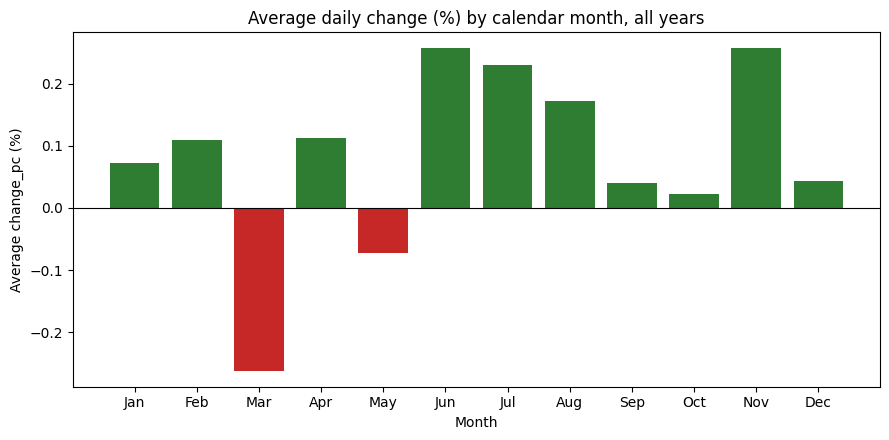

In [43]:
import matplotlib
import matplotlib.pyplot as plt
p = a2.toPandas().sort_values('month_num')
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#2e7d32' if v >= 0 else '#c62828' for v in p.avg_change_pc]
ax.bar(p.month_name.str[:3], p.avg_change_pc, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Average daily change (%) by calendar month, all years')
ax.set_xlabel('Month'); ax.set_ylabel('Average change_pc (%)')
plt.tight_layout()
plt.savefig(f'{DOCS}/analysis2_avg_change_by_month.png', dpi=200)
plt.show()

# Task 3 : Sample and prepare the final-sprint handoff

**Target:** `target_up` = 1 if the **next trading day's** close is higher than today's close, 0 if lower. Days where the next close is unchanged are excluded (no direction); the last day of the series has no next day. Counts for each exclusion are recorded below.

**Prediction time:** end of trading day *t* (after the close). Only information up to and including day *t*  is used.

**Features (all known at prediction time):** `ret_1d` (today's `change_pc`), `ret_lag1`, `ret_lag2`, `ret_mean_90`, `ret_std_90` (trailing 90 trading days incl. today), `range_pct` ((high-low)/close), `vol_ratio_20` (today's volume / trailing 20-day mean), `month`, `dow`.

**Kept out of the feature set:** `next_close` and anything derived from it (reveals the outcome); `name`, `date` (IDs); `close`, `minute_rows` (audit metadata, saved separately).

**Split:** one **time split** at the 80% point of the modelled trading dates (train earlier, test later), with a one-day purge so no training label uses a close from the test period. Sampling is done on the **training** data only. Any later imputation or scaling must be fitted on training only.

In [44]:
w   = Window.partitionBy('name').orderBy('date')
w90 = w.rowsBetween(-89, 0)
w20 = w.rowsBetween(-19, 0)

feat = (daily_df
    .withColumn('next_close', F.lead('close').over(w))
    .withColumn('ret_1d',    F.col('change_pc'))
    .withColumn('ret_lag1',  F.lag('change_pc', 1).over(w))
    .withColumn('ret_lag2',  F.lag('change_pc', 2).over(w))
    .withColumn('ret_mean_90', F.when(F.count('change_pc').over(w90) == 90, F.avg('change_pc').over(w90)))
    .withColumn('ret_std_90',  F.when(F.count('change_pc').over(w90) == 90, F.stddev('change_pc').over(w90)))
    .withColumn('range_pct',   (F.col('high') - F.col('low')) / F.col('close') * 100)
    .withColumn('vol_ratio_20', F.when(F.count('volume').over(w20) == 20, F.col('volume') / F.avg('volume').over(w20)))
    .withColumn('month', F.month('date'))
    .withColumn('dow',   F.dayofweek('date'))
    .withColumn('target_up', F.when(F.col('next_close') > F.col('close'), 1)
                              .when(F.col('next_close') < F.col('close'), 0)))

FEATURES = ['ret_1d', 'ret_lag1', 'ret_lag2', 'ret_mean_90', 'ret_std_90', 'range_pct', 'vol_ratio_20', 'month', 'dow']
TARGET   = 'target_up'
IDS      = ['name', 'date']
AUDIT    = ['name', 'date', 'close', 'next_close', 'minute_rows']

n_all   = feat.count()
n_last  = feat.filter(F.col('next_close').isNull()).count()
n_flat  = feat.filter(F.col('next_close').isNotNull() & F.col(TARGET).isNull()).count()
no_feat = F.lit(False)
for c in FEATURES:
    no_feat = no_feat | F.col(c).isNull()
n_warm  = feat.filter(F.col(TARGET).isNotNull() & no_feat).count()
modeled = feat.filter(F.col(TARGET).isNotNull() & ~no_feat)
n_model = modeled.count()
print(dict(daily_rows=n_all, no_next_day=n_last, flat_next_close=n_flat, warmup_missing_features=n_warm, modeled=n_model))
assert n_all - n_last - n_flat - n_warm == n_model

model_df = modeled.select(IDS + FEATURES + [TARGET])
audit_df = modeled.select(AUDIT)
model_df.cache()
model_df.show(3)
print('label balance:'); model_df.groupBy(TARGET).count().show()

{'daily_rows': 2769, 'no_next_day': 1, 'flat_next_close': 16, 'warmup_missing_features': 89, 'modeled': 2663}
+----------+----------+------+--------+--------+--------------------+------------------+-----------------+------------------+-----+---+---------+
|      name|      date|ret_1d|ret_lag1|ret_lag2|         ret_mean_90|        ret_std_90|        range_pct|      vol_ratio_20|month|dow|target_up|
+----------+----------+------+--------+--------+--------------------+------------------+-----------------+------------------+-----+---+---------+
|APOLLOHOSP|2015-06-15|  0.59|   -2.96|     1.0|-0.11688888888888885|2.4323441527471488|4.064080944350763| 0.556482490036367|    6|  2|        1|
|APOLLOHOSP|2015-06-16|  0.43|    0.59|   -2.96|-0.06855555555555552|2.3989129378524257|3.526152296196793|1.0177303179641428|    6|  3|        1|
|APOLLOHOSP|2015-06-17|  0.03|    0.43|    0.59| -0.0726666666666667| 2.398417924242112|2.194804649796455|0.8907538799600695|    6|  4|        0|
+----------+--

In [45]:
dates = [r['date'] for r in model_df.select('date').distinct().orderBy('date').collect()]
idx = int(0.8 * len(dates))
cutoff_date = dates[idx]          # first test date
purge_date  = dates[idx - 1]      # last pre-cutoff date: dropped so its label cannot use a test-period close
print('modelled dates:', len(dates), '| first', dates[0], '| last', dates[-1])
print('purged date   :', purge_date)
print('test starts   :', cutoff_date)

train_df = model_df.filter(F.col('date') < purge_date)
purged   = model_df.filter(F.col('date') == purge_date)
test_df  = model_df.filter(F.col('date') >= cutoff_date)

n_train, n_purged, n_test = train_df.count(), purged.count(), test_df.count()
print(dict(train=n_train, purged=n_purged, test=n_test, total=n_model, train_share=round(n_train / n_model, 3)))
max_train = train_df.agg(F.max('date')).first()[0]; min_test = test_df.agg(F.min('date')).first()[0]
print('max(train.date) < min(test.date):', max_train < min_test, max_train, min_test)
names_tr = {r[0] for r in train_df.select('name').distinct().collect()}
names_te = {r[0] for r in test_df.select('name').distinct().collect()}
print('stocks in train/test:', names_tr, names_te, '| coverage ok:', names_tr == names_te)
assert n_train + n_purged + n_test == n_model and max_train < min_test
print('label balance train:'); train_df.groupBy(TARGET).count().show()
print('label balance test :'); test_df.groupBy(TARGET).count().show()

modelled dates: 2663 | first 2015-06-15 | last 2026-04-07
purged date   : 2024-02-06
test starts   : 2024-02-07
{'train': 2129, 'purged': 1, 'test': 533, 'total': 2663, 'train_share': 0.799}
max(train.date) < min(test.date): True 2024-02-05 2024-02-07
stocks in train/test: {'APOLLOHOSP'} {'APOLLOHOSP'} | coverage ok: True
label balance train:
+---------+-----+
|target_up|count|
+---------+-----+
|        1| 1075|
|        0| 1054|
+---------+-----+

label balance test :
+---------+-----+
|target_up|count|
+---------+-----+
|        1|  263|
|        0|  270|
+---------+-----+



## Development sample (training data only)

Population sampled: the training rows above (before the purge row and without any test rows). A seed alone does not pin the exact rows if inputs or partitioning change, so the selected rows are saved as Parquet and that file is the one to reuse.

In [46]:
FRACTION = 0.2
# sort + single partition first: sample() depends on row layout, so this makes the selection repeatable for the same input
dev_sample = (train_df.orderBy('name', 'date').coalesce(1)
                      .sample(withReplacement=False, fraction=FRACTION, seed=131))
n_sample = dev_sample.count()
print(f'population = training rows ({n_train}), fraction = {FRACTION}, seed = 131 -> sample rows = {n_sample} ({n_sample / n_train:.3f})')
assert n_sample > 0

def compare_groups(src, smp, col, label):
    ns, nm = src.count(), smp.count()
    s = src.groupBy(col).count().withColumnRenamed('count', 'source_count')
    p = smp.groupBy(col).count().withColumnRenamed('count', 'sample_count')
    j = s.join(p, col, 'left').na.fill(0, ['sample_count'])
    return (j.select(F.lit(label).alias('group_type'), F.col(col).cast('string').alias('group_value'),
                     'source_count', F.round(F.col('source_count') / ns * 100, 2).alias('source_pct'),
                     'sample_count', F.round(F.col('sample_count') / nm * 100, 2).alias('sample_pct'))
              .withColumn('pct_diff', F.round(F.col('sample_pct') - F.col('source_pct'), 2))
              .withColumn('note', F.when(F.col('sample_count') == 0, 'missing from sample')
                                   .when(F.abs(F.col('pct_diff')) >= 3, 'proportion shifted by 3+ points')
                                   .otherwise('')))

src = train_df.withColumn('year', F.year('date'))
smp = dev_sample.withColumn('year', F.year('date'))
sample_cmp = (compare_groups(src, smp, TARGET, 'target_up')
              .unionByName(compare_groups(src, smp, 'year', 'year'))
              .orderBy('group_type', 'group_value'))
sample_cmp.show(30, False)
save_csv(sample_cmp, f'{OUT}/sample_comparison.csv')

population = training rows (2129), fraction = 0.2, seed = 131 -> sample rows = 397 (0.186)
+----------+-----------+------------+----------+------------+----------+--------+----+
|group_type|group_value|source_count|source_pct|sample_count|sample_pct|pct_diff|note|
+----------+-----------+------------+----------+------------+----------+--------+----+
|target_up |0          |1054        |49.51     |193         |48.61     |-0.9    |    |
|target_up |1          |1075        |50.49     |204         |51.39     |0.9     |    |
|year      |2015       |137         |6.43      |29          |7.3       |0.87    |    |
|year      |2016       |246         |11.55     |44          |11.08     |-0.47   |    |
|year      |2017       |245         |11.51     |41          |10.33     |-1.18   |    |
|year      |2018       |244         |11.46     |51          |12.85     |1.39    |    |
|year      |2019       |242         |11.37     |38          |9.57      |-1.8    |    |
|year      |2020       |252         |11

In [47]:
paths = {'train': f'{PREP}/train.parquet', 'test': f'{PREP}/test.parquet',
         'dev_sample_train': f'{PREP}/dev_sample_train.parquet', 'audit': f'{PREP}/audit.parquet'}
train_df.write.mode('overwrite').parquet(paths['train'])
test_df.write.mode('overwrite').parquet(paths['test'])
dev_sample.write.mode('overwrite').parquet(paths['dev_sample_train'])
audit_df.write.mode('overwrite').parquet(paths['audit'])

src_df = {'train': train_df, 'test': test_df, 'dev_sample_train': dev_sample, 'audit': audit_df}
rb_report = {}
for k, pth in paths.items():
    rb = spark.read.parquet(pth)
    rb_report[k] = dict(count=rb.count(), expected=src_df[k].count(), same_schema=rb.dtypes == src_df[k].dtypes)
    print(k, rb_report[k])
up_src = train_df.agg(F.sum(TARGET)).first()[0]
up_rb  = spark.read.parquet(paths['train']).agg(F.sum(TARGET)).first()[0]
print('project-specific total: up-days in train', up_src, '== read-back', up_rb, up_src == up_rb)
assert all(v['count'] == v['expected'] and v['same_schema'] for v in rb_report.values()) and up_src == up_rb

train {'count': 2129, 'expected': 2129, 'same_schema': True}
test {'count': 533, 'expected': 533, 'same_schema': True}
dev_sample_train {'count': 397, 'expected': 397, 'same_schema': True}
audit {'count': 2663, 'expected': 2663, 'same_schema': True}
project-specific total: up-days in train 1075 == read-back 1075 True


## Checks for Tasks 2 and 3


In [48]:
checks2 = []
def check2(cat, desc, value, note=''):
    checks2.append(dict(category=cat, description=desc, value=value, note=note))

check2('Row Count', 'Minute rows read (Analysis 1)', n_raw_minute)
check2('Row Count', 'Minute rows rejected by PA3 validation rules', n_rejected_minute, 'each row counted once under the first failed rule')
check2('Row Count', 'Minute rows valid', n_valid_minute)
check2('Row Count', 'Valid minute rows with price_change = none (excluded from Analysis 1)', n_none_minute)
check2('Row Count', 'Comparable rows (increased + decreased)', int(a1.agg(F.sum('compared_rows')).first()[0]))
check2('Row Count', 'Daily rows before / after domain filter', f'{n_daily_raw} / {n_daily}')
check2('Row Count', 'Task 3 funnel: daily rows', n_all)
check2('Row Count', 'Task 3 funnel: no next day (last day)', n_last)
check2('Row Count', 'Task 3 funnel: flat next close (no direction)', n_flat, 'excluded; counted after last-day rows')
check2('Row Count', 'Task 3 funnel: warm-up rows missing 90/20-day features', n_warm, 'counted after the two exclusions above')
check2('data type', 'features are numeric, target is int', str({c: t for c, t in model_df.dtypes if c != 'name'}))
check2('missing', 'Null values in modelled features/target', model_df.filter(no_feat | F.col(TARGET).isNull()).count())
check2('domain check', 'target_up values', str(sorted(r[0] for r in model_df.select(TARGET).distinct().collect())), 'expected [0, 1]')
check2('domain check', 'month_num range in analysis_2', f"{a2.agg(F.min('month_num')).first()[0]}-{a2.agg(F.max('month_num')).first()[0]}")
check2('domain check', 'PA3 baseline label mismatches', n_mismatch, 'recomputed label vs supplied price_change')
check2('key uniqueness', '(name, date) unique in daily table', daily_df.groupBy('name', 'date').count().filter('count > 1').count() == 0)
check2('join', 'duplicate lookup keys in month_lookup', dup_keys)
check2('join', 'unmatched daily rows after join', unmatched)
check2('join', 'row count before/after join', f'{n_before} / {n_after}')
check2('window', 'Jan average change_pc: Spark vs pandas', f"{spark_jan['avg_change_pc']} vs {round(jan.mean(), 4)}")
check2('window', 'PA3 comparison: all 12 months match', bool(m.count_match.all() and m.ratio_match.all()))
check2('sampling', 'fraction / seed / population', f'{FRACTION} / 131 / training rows ({n_train})')
check2('sampling', 'sample rows', n_sample, f'{n_sample / n_train:.3f} of training rows')
check2('split', 'train / purged / test rows', f'{n_train} / {n_purged} / {n_test}')
check2('split', 'cutoff (first test date) / purged date', f'{cutoff_date} / {purge_date}')
check2('split', 'max(train.date) < min(test.date)', bool(max_train < min_test))
check2('split', 'every stock in train and test', names_tr == names_te)
for k, v in rb_report.items():
    check2('parquet', f'{k} read-back count / same schema', f"{v['count']} / {v['same_schema']}")
check2('parquet', 'project total: up-days in train, source vs read-back', f'{up_src} / {up_rb}')

prev = checks if isinstance(checks, pd.DataFrame) else pd.DataFrame(checks)
all_checks = pd.concat([prev, pd.DataFrame(checks2)], ignore_index=True)
all_checks.to_csv(f'{OUT}/quality_checks.csv', index=False)
print(len(all_checks), 'checks written to', f'{OUT}/quality_checks.csv')

50 checks written to /content/7thStWolf-Nifty100-Stock/pa4/out/quality_checks.csv


# Task 4


We compare Analysis 1 in PySpark and DuckDB by doing the following:
1. Verify correctness for all result rows using consistent columns, ordering, and numeric tolerance
2. Record three runs per tool on the same records, query rules, and input format. We also reuse PA3 DuckDB timings only if the DuckDB timings and timing boundary matches. If it's different, we have to rerun.
3. Time input reading using the same scope we had in the DuckDB run.

`benchmark.tsv` also saved with columns:
`implementation,environment,input_rows,input_bytes,format,run,elapsed_seconds,output_rows,result_verified`

In [49]:
import duckdb
import time
import os
import statistics
import pandas as pd
import numpy as np

print("DuckDB version:", duckdb.__version__)
print("Spark version:", spark.version)
print("Spark master version:", spark.sparkContext.master)

DuckDB version: 1.3.2
Spark version: 4.0.1
Spark master version: local[2]


Verify that benchmark input is available

In [50]:
MINUTE_FILE = f'{MINUTE_PATH}/sample.tsv'

assert os.path.exists(MINUTE_FILE), "Input TSV not found."

print("Benchmark input:", MINUTE_FILE)

Benchmark input: /content/7thStWolf-Nifty100-Stock/pa3/data/sample/sample.tsv


Benchmark Setup

In [51]:
MINUTE_FILE = f'{MINUTE_PATH}/sample.tsv'
BENCHMARK_FILE = f'{OUT}/benchmark.csv'

assert os.path.exists(MINUTE_FILE), "Input TSV not found!"

print("Input:", MINUTE_FILE)
print("Output:", BENCHMARK_FILE)

Input: /content/7thStWolf-Nifty100-Stock/pa3/data/sample/sample.tsv
Output: /content/7thStWolf-Nifty100-Stock/pa4/out/benchmark.csv


DuckDB Query

In [52]:
duckdb_query = """
SELECT
  CAST(substr(date, 6, 2) AS INTEGER) AS month,
    SUM(CASE
      WHEN lower(price_change) = 'increased' THEN 1
	    ELSE 0
    END) AS increase_count,
    COUNT(*) AS compared_rows,
    ROUND (
      SUM(CASE
	      WHEN lower(price_change) = 'increased' THEN 1
	      ELSE 0
      END) * 1.0 / COUNT(*), 4
    ) AS increase_ratio
FROM read_csv(
  ?,
  delim = '\\t',
  header = true,
  all_varchar = true
)
WHERE lower(price_change) IN ('increased', 'decreased')
GROUP BY month
ORDER BY month
"""

Test DuckDB

In [53]:
duckdb_res = duckdb.connect().execute(
    duckdb_query, [MINUTE_FILE]
).fetchdf()

print(duckdb_res.to_string(index=False))

 month  increase_count  compared_rows  increase_ratio
     1         40634.0          81372          0.4994
     2         41969.0          84465          0.4969
     3         42240.0          84758          0.4984
     4         37039.0          73972          0.5007
     5         39971.0          80460          0.4968
     6         40141.0          80905          0.4961
     7         41138.0          81898          0.5023
     8         39778.0          80091          0.4967
     9         39154.0          78564          0.4984
    10         37761.0          75986          0.4969
    11         37787.0          75913          0.4978
    12         40344.0          81506          0.4950


PySpark Benchmark

In [54]:
def run_pyspark_analysis():
    # Read original TSV for every run
    df = (spark.read
	  		.option('header', True)
	  		.option('sep', '\t')
				.csv(MINUTE_FILE))

    pc = F.lower(F.col('price_change'))

    res = (df
	      .withColumn('pc', pc)
	      .filter(F.col('pc').isin('increased', 'decreased'))
	      .withColumn('month', F.substring('date', 6, 2).cast('int'))
	      .groupBy('month')
	      .agg(
	      F.sum(
		    		F.when(F.col('pc') == 'increased', 1).otherwise(0)
	        ).cast('long').alias('increase_count'),
	      F.count('*').alias('compared_rows')
	      )
	      .withColumn(
	          'increase_ratio', F.round(F.col('increase_count') / F.col('compared_rows'), 4)
	      )
	      .orderBy('month')
    )

		# Cache and force Spark to finish executing query
    res.persist()
    output_rows = res.count()

    return res, output_rows

Create DuckDB benchmark

In [55]:
def run_duckdb_analysis():
    connection = duckdb.connect()

    res = connection.execute(
        duckdb_query, [MINUTE_FILE]
    )

    return connection, res

Verify timed results against existing PySpark output

In [56]:
def normalize_result(df):
    res = df.copy()
    res = res.sort_values('month').reset_index(drop=True)

    res['month'] = res['month'].astype(int)
    res['increase_count'] = res['increase_count'].astype(int)
    res['compared_rows'] = res['compared_rows'].astype(int)
    res['increased_ratio'] = res['increase_ratio'].astype(float)

    return res[
	['month', 'increase_count', 'compared_rows', 'increase_ratio']
    ]

expected = normalize_result(duckdb_res)

def verify_result(res):
    actual = normalize_result(res)

    # Check ordering of months and integer count
    same_counts = (
        actual['month'].equals(expected['month']) and
        actual['increase_count'].equals(expected['increase_count']) and
        actual['compared_rows'].equals(expected['compared_rows'])
    )

    # Check ratios
    same_ratios = np.allclose(
        actual['increase_ratio'],
        expected['increase_ratio'],
        atol = 0.0001,
    )

    return same_counts and same_ratios

Run A1 once using PySpark and DuckDB and checking that both results match expected output.

In [57]:
# PySpark warmup
pyspark_warmup, pyspark_rows = run_pyspark_analysis()

pyspark_warmup_df = pyspark_warmup.toPandas()

print("PySpark correctness:", verify_result(pyspark_warmup_df))

pyspark_warmup.unpersist()

# DuckDB warmup
duckdb_connection, duckdb_res = run_duckdb_analysis()

duckdb_warmup_df = duckdb_res.fetchdf()

print("DuckDB correctness:", verify_result(duckdb_warmup_df))

duckdb_connection.close()


PySpark correctness: True
DuckDB correctness: True


Running each implementation 3 times and record execution time.

All measured runs are in `pa4/out/benchmark.csv`

In [58]:
benchmark_res = []

INPUT_BYTES = os.path.getsize(MINUTE_FILE)
INPUT_ROWS = sum(1 for _ in open(MINUTE_FILE)) - 1

for implementation, function in [
    ('PySpark', run_pyspark_analysis),
    ('DuckDB', run_duckdb_analysis)
]:

    for run_number in range(1, 4):
        start = time.perf_counter()
        res = function()
        elapsed = time.perf_counter() - start

        # Convert and verify results
        if implementation == 'PySpark':
            actual_res = res[0]
            output_rows = res[1]
            actual_res = actual_res.toPandas()
            res[0].unpersist()
        else:
            connection, query_res = res
            actual_res = query_res.fetchdf()
            output_rows = len(actual_res)
            connection.close()

        verified = verify_result(actual_res)

        benchmark_res.append({
	          'implementation': implementation,
            'environment': 'Colab',
           	'input_rows': INPUT_ROWS,
	          'input_bytes': INPUT_BYTES,
            'format': 'tsv',
	          'run': run_number,
	          'elapsed_seconds': round(elapsed, 4),
            'output_rows': output_rows,
	          'result_verified': verified
	    })

        print(f"{implementation} | Run {run_number} | "f"{elapsed:.4f} seconds | Verified: {verified}")

benchmark_df = pd.DataFrame(benchmark_res)

benchmark_df = benchmark_df[
    [
        'implementation',
        'environment',
        'input_rows',
        'input_bytes',
        'format',
        'run',
        'elapsed_seconds',
        'output_rows',
        'result_verified'
    ]
]

benchmark_df.to_csv(BENCHMARK_FILE, index=False)

print("\nBenchmark saved to:", BENCHMARK_FILE)
print(benchmark_df.to_string(index=False))

assert benchmark_df['result_verified'].all()

PySpark | Run 1 | 3.6132 seconds | Verified: True
PySpark | Run 2 | 2.8331 seconds | Verified: True
PySpark | Run 3 | 2.3469 seconds | Verified: True
DuckDB | Run 1 | 0.6216 seconds | Verified: True
DuckDB | Run 2 | 0.5415 seconds | Verified: True
DuckDB | Run 3 | 0.5593 seconds | Verified: True

Benchmark saved to: /content/7thStWolf-Nifty100-Stock/pa4/out/benchmark.csv
implementation environment  input_rows  input_bytes format  run  elapsed_seconds  output_rows  result_verified
       PySpark       Colab     1033587     87079423    tsv    1           3.6132           12             True
       PySpark       Colab     1033587     87079423    tsv    2           2.8331           12             True
       PySpark       Colab     1033587     87079423    tsv    3           2.3469           12             True
        DuckDB       Colab     1033587     87079423    tsv    1           0.6216           12             True
        DuckDB       Colab     1033587     87079423    tsv    2        

- Each implementation produces 12 output rows
- All six runs pass correctness check

Calculate median execution times

In [59]:
summary = benchmark_df.groupby('implementation')['elapsed_seconds'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

print(summary)

                    mean  median       std     min     max
implementation                                            
DuckDB          0.574133  0.5593  0.042060  0.5415  0.6216
PySpark         2.931067  2.8331  0.638809  2.3469  3.6132


Summary statistics should match the six timings.